In [2]:
import pandas as pd
from glob import glob
import seaborn as sns
import aquarel
import matplotlib.pyplot as plt

In [3]:
data = []
for f in glob("../data/interim/logs_deep/*/version_*/metrics.csv"):
    version = f.split("/")[-2].split("_")[-1]
    model, topic = f.split("/")[-3].rsplit("-", 1)
    model_type, model_name = model.split("-", 1)
    model_name, tuning_type = model_name.rsplit("-", 1)
    tmp = (
        pd.read_csv(f)
        .assign(
            model_type=model_type,
            model_name=model_name,
            topic=topic,
            tuning_type=tuning_type,
            version=version,
        )
    )
    try:
        data.append(tmp.loc[:, ["model_type", "model_name", "topic", "tuning_type", "version", "precision", "recall", "accuracy", "f1"]])
    except:
        pass


df = (
    pd.concat(data)
    .dropna(subset=["precision", "recall", "accuracy", "f1"])
    .sort_values(["model_type", "model_name", "topic", "tuning_type", "version"], ascending=[True, True, True, True, False])
    .drop_duplicates(subset=["model_type", "model_name", "topic", "tuning_type"], keep="first")
    .drop(columns=["version"])
    .merge(
        (
            pd.read_parquet("../data/interim/run_evals.parquet")
            .loc[:, ["query", "NDCG@10"]]
            .groupby("query")
            .mean()
            .reset_index()
            .rename(columns={"query": "topic", "NDCG@10": "topic_difficulty"})
        ),
        left_on="topic",
        right_on="topic",
        how="left",
    )
    .dropna(subset=["topic_difficulty"])
)

In [4]:
(
    df
    .loc[:, ["model_type", "model_name", "topic", "tuning_type", "f1", "precision", "recall", "accuracy"]]
    .assign(identifier=lambda df: df.apply(lambda row: f"{row['model_type']} ({row['tuning_type']})", axis=1))
    .melt(id_vars=["identifier", "topic"])
)

,identifier,topic,variable,value
0,bi (lora),301,model_type,bi
1,bi (native),301,model_type,bi
2,bi (lora),304,model_type,bi
3,bi (native),304,model_type,bi
4,bi (lora),306,model_type,bi
...,...,...,...,...
2011,mono (native),683,accuracy,0.988304
2012,mono (lora),688,accuracy,0.953488
2013,mono (native),688,accuracy,0.930233
2014,mono (lora),700,accuracy,0.948529


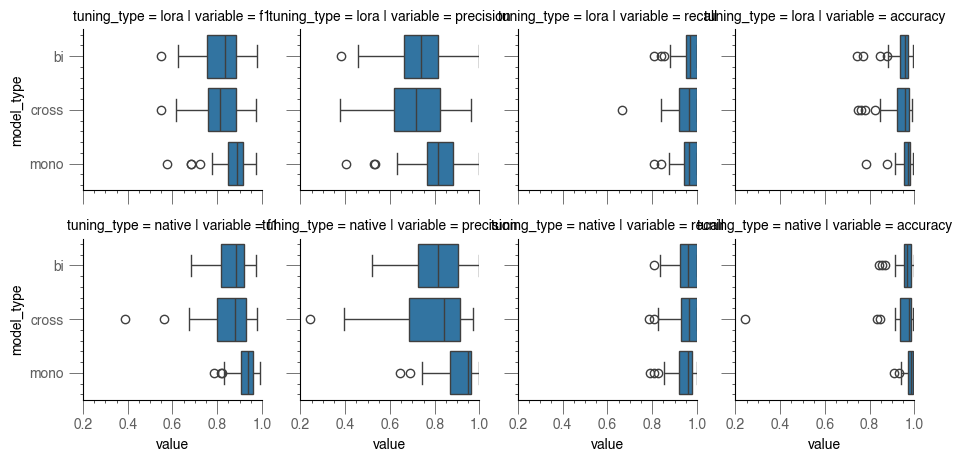

In [17]:
with (
    aquarel
    .load_theme("minimal_light")
    .set_ticks(draw_minor=True)
    .set_transforms(trim=True, offset=0)
):
    g = sns.FacetGrid(data=(
        df
        .loc[:, ["model_type", "tuning_type", "topic", "f1", "precision", "recall", "accuracy"]]
        .melt(id_vars=["model_type", "tuning_type", "topic"])
    ), col="variable", row="tuning_type", aspect=(12 / 6 / 2), height=2.36, sharex=True, legend_out=True, xlim=(0.2, 1), ylim=(0, 1))
    g.map(
        sns.boxplot,
        "value",
        "model_type",
        order=["bi", "cross", "mono"],
    )

plt.show()

In [6]:
(
    df
    .loc[:, ["model_type", "tuning_type", "f1", "recall", "precision", "accuracy", "topic_difficulty"]]
    .groupby(["model_type", "tuning_type"])
    .corr(method="spearman")
    .reset_index()
    .query("level_2 == 'topic_difficulty'")
    .drop(columns=["topic_difficulty", "level_2"])
    .rename(columns={
        "f1": "rho(f1, topic_difficulty)",
        "precision": "rho(precision, topic_difficulty)",
        "recall": "rho(recall, topic_difficulty)",
        "accuracy": "rho(accuracy, topic_difficulty)"
    })
    .query("tuning_type != 'native'").drop(columns=["tuning_type"])
)

,model_type,"rho(f1, topic_difficulty)","rho(recall, topic_difficulty)","rho(precision, topic_difficulty)","rho(accuracy, topic_difficulty)"
4,bi,0.124077,-0.121828,0.100906,0.035389
14,cross,0.114492,-0.036775,0.125767,0.037994
24,mono,0.136080,-0.069024,0.167775,0.073873


In [7]:
import pandas as pd
import numpy as np
from scipy.stats import pearsonr
from statsmodels.stats.multitest import multipletests
from itertools import product

def grouped_cross_corr_bonferroni(grouped_df, cols1, cols2):
    """Calculate Pearson correlations between cols1 and cols2 with Bonferroni correction"""

    def _group_corr(group):
        pairs = list(product(cols1, cols2))

        results = []
        p_vals = []

        for col1, col2 in pairs:
            mask = group[[col1, col2]].notna().all(axis=1)
            if mask.sum() < 3:
                corr, p_val = np.nan, np.nan
            else:
                corr, p_val = pearsonr(group.loc[mask, col1], group.loc[mask, col2])

            results.append({
                'var1': col1, 'var2': col2,
                'correlation': corr, 'p_value': p_val
            })
            p_vals.append(p_val)

        # Bonferroni correction
        p_vals_clean = [p for p in p_vals if not np.isnan(p)]
        if p_vals_clean:
            _, p_corrected, _, _ = multipletests(p_vals_clean, method='bonferroni')
            p_corr_iter = iter(p_corrected)

            for result in results:
                if not np.isnan(result['p_value']):
                    result['p_bonferroni'] = next(p_corr_iter)
                else:
                    result['p_bonferroni'] = np.nan
        else:
            for result in results:
                result['p_bonferroni'] = np.nan

        return pd.DataFrame(results)

    return grouped_df.apply(_group_corr).reset_index()

In [8]:
(
    grouped_cross_corr_bonferroni(
        grouped_df = (
            df
            .query("tuning_type == 'lora'")
            .loc[:, ["model_type", "f1", "recall", "precision", "accuracy", "topic_difficulty"]]
            .groupby(["model_type"])
        ),
        cols1=["recall", "precision", "accuracy", "f1"],
        cols2=["topic_difficulty"]
    )
    .drop(columns=["level_1", "var2", "p_value"])
    .melt(id_vars=["model_type", "var1"])
    .pivot(
        index="var1",
        columns=["model_type", "variable"],
        values="value",
    )
    .round(2)
)

/var/folders/54/8lplw84d1sbgcm1wmd2rgyd40000gn/T/ipykernel_62184/1683708590.py:46: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return grouped_df.apply(_group_corr).reset_index()


model_type,bi,cross,mono,bi,cross,mono
variable,correlation,correlation,correlation,p_bonferroni,p_bonferroni,p_bonferroni
var1,,,,,,
accuracy,0.10,0.06,0.01,1.0,1.0,1.0
f1,0.13,0.14,0.13,1.0,1.0,1.0
precision,0.14,0.12,0.13,1.0,1.0,1.0
recall,-0.01,0.05,0.02,1.0,1.0,1.0
